In [1]:
suppressMessages(library(DESeq2))
suppressMessages(library(ggplot2))
suppressMessages(library(sva))

In [2]:
df1 <- read.csv("../../results/10_compare_with_public_data/01_create_pseudo_bulk/pseudo_bulk_counts.csv", 
row.names = 1)
mt_genes <- grepl("^MT-", rownames(df1))
df1 <- df1[!mt_genes, ]

In [5]:
df2 <- read.csv("../../results/10_compare_with_public_data/05_Jianbo_Qing_JASN_2026/pbm.tsv", sep='\t', row.names = 1)

In [6]:
head(df2)

,Con1,Con2,Con3,LN1,LN2,LN3
,<int>,<int>,<int>,<int>,<int>,<int>
RP11-34P13.7,30,32,62,66,88,100
FO538757.2,2029,3399,3285,652,10,0
AP006222.2,207,228,385,230,77,59
RP4-669L17.10,18,19,27,28,20,6
RP5-857K21.4,1424,1474,2284,1513,519,316
RP11-206L10.4,4,0,4,3,0,4


In [7]:
sel_genes <- intersect(rownames(df1), rownames(df2))

length(sel_genes)

[1] 16475

In [8]:
df1 <- df1[sel_genes, ]
df2 <- df2[sel_genes, ]

df <- cbind(df1, df2)

In [10]:
colnames(df)

[1] "sample_15837"         "sample_15852"         "sample_16512"        
 [4] "sample_21022"         "sample_8262"          "sample_B23.03794.5"  
 [7] "sample_B23.05785.7.1" "sample_B23.05785.7.2" "sample_X1842"        
[10] "sample_X1845"         "sample_X1899"         "sample_X1912"        
[13] "Con1"                 "Con2"                 "Con3"                
[16] "LN1"                  "LN2"                  "LN3"

In [11]:
coldata <- data.frame(
  condition = c(
    "SRC", "SRC", "SRC", "SRC", "SRC",
    "Normal", "Normal", "Normal",
    "LN", "LN", "LN", "LN", 
    "Normal", "Normal", "Normal",
    "LN", "LN", "LN"
  ),
  batch = c(
    "Ours", "Ours", "Ours", "Ours", "Ours",
    "Ours", "Ours", "Ours",
    "Ours", "Ours", "Ours", "Ours",
    "Jianbo_Qing_JASN_2026", 
    "Jianbo_Qing_JASN_2026", 
    "Jianbo_Qing_JASN_2026",
    "Jianbo_Qing_JASN_2026", 
    "Jianbo_Qing_JASN_2026", 
    "Jianbo_Qing_JASN_2026"),
  row.names = c("sample_15837", "sample_15852", "sample_16512", "sample_21022", "sample_8262",
  "sample_B23.03794.5", "sample_B23.05785.7.1", "sample_B23.05785.7.2",
  "sample_X1842","sample_X1845", "sample_X1899", "sample_X1912", 
  "Con1", "Con2", "Con3",
  "LN1", "LN2", "LN3")

)

In [12]:
head(coldata)

,condition,batch
,<chr>,<chr>
sample_15837,SRC,Ours
sample_15852,SRC,Ours
sample_16512,SRC,Ours
sample_21022,SRC,Ours
sample_8262,SRC,Ours
sample_B23.03794.5,Normal,Ours


In [46]:
dds <- DESeqDataSetFromMatrix(
  countData = df,
  colData = coldata,
  design = ~ batch + condition
)

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


In [47]:
dds

class: DESeqDataSet 
dim: 16475 18 
metadata(1): version
assays(1): counts
rownames(16475): SAMD11 NOC2L ... KDM5D EIF1AY
rowData names(0):
colnames(18): sample_15837 sample_15852 ... LN2 LN3
colData names(2): condition batch

In [48]:
# optional but recommended: remove very low-count genes
# keep <- rowSums(counts(dds) >= 10) >= 5
# dds <- dds[keep, ]

# run DESeq pipeline
dds <- DESeq(dds)

# variance stabilizing transform
vsd <- vst(dds, blind = FALSE)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [49]:
vsd

class: DESeqTransform 
dim: 16475 18 
metadata(1): version
assays(1): ''
rownames(16475): SAMD11 NOC2L ... KDM5D EIF1AY
rowData names(30): baseMean baseVar ... maxCooks dispFit
colnames(18): sample_15837 sample_15852 ... LN2 LN3
colData names(3): condition batch sizeFactor

In [50]:
pcaData <- plotPCA(vsd, ntop=16475,
intgroup = "condition", returnData = TRUE)
percentVar <- round(100 * attr(pcaData, "percentVar"))

using ntop=16475 top features by variance



In [51]:
library(ggrepel)

In [52]:
p <- ggplot(pcaData, aes(PC1, PC2, color = condition, label = name)) +
  geom_point(size = 3) +
  geom_text(vjust = -0.8, size = 3) +
  xlab(paste0("PC1: ", percentVar[1], "% variance")) +
  ylab(paste0("PC2: ", percentVar[2], "% variance")) +
  theme_classic()

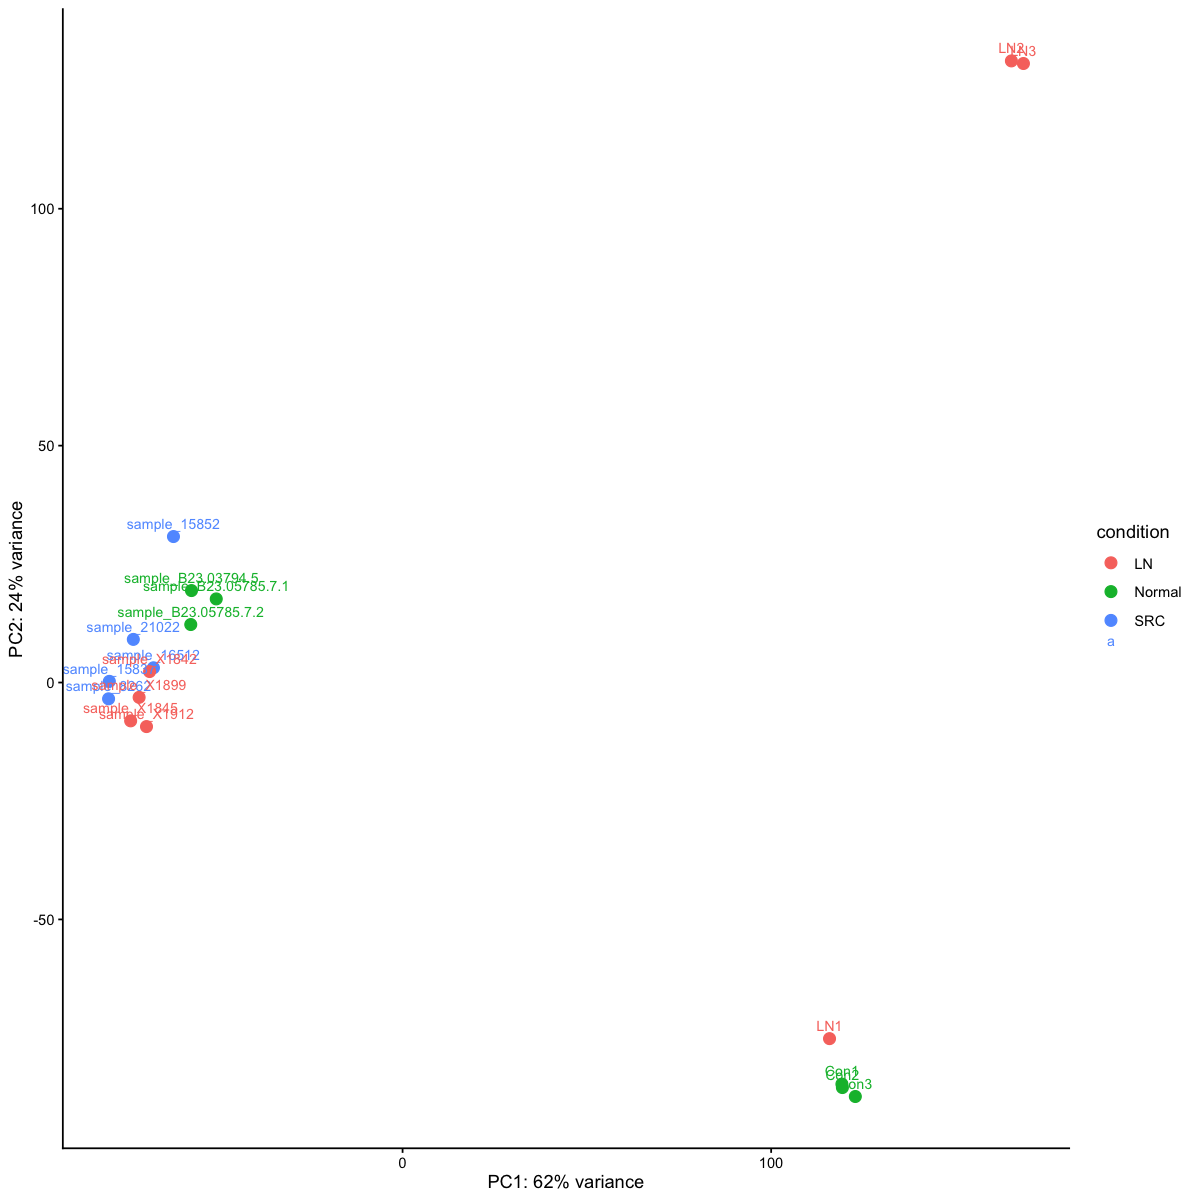

In [53]:
options(repr.plot.width=10, repr.plot.height=10)

print(p)

In [54]:
vsd <- vst(dds, blind = TRUE)
mat <- assay(vsd)
pca <- prcomp(t(mat), scale. = FALSE)

In [55]:
pc1_loadings <- pca$rotation[, "PC1"]

top10_pc1 <- sort(abs(pc1_loadings), decreasing = TRUE)[1:10]
top10_genes <- names(top10_pc1)

print(top10_genes)

 [1] "IGKC"   "IGHG1"  "TMSB4X" "GPC5"   "VIM"    "PTH2R"  "S100A6" "EEF1G" 
 [9] "TMSB10" "TIMP1" 


In [61]:
batch <- coldata$batch
mod <- model.matrix(~ condition, data = coldata)

modcombat = model.matrix(~1, data=coldata)

In [57]:
batch

[1] "Ours"                  "Ours"                  "Ours"                 
 [4] "Ours"                  "Ours"                  "Ours"                 
 [7] "Ours"                  "Ours"                  "Ours"                 
[10] "Ours"                  "Ours"                  "Ours"                 
[13] "Jianbo_Qing_JASN_2026" "Jianbo_Qing_JASN_2026" "Jianbo_Qing_JASN_2026"
[16] "Jianbo_Qing_JASN_2026" "Jianbo_Qing_JASN_2026" "Jianbo_Qing_JASN_2026"

In [62]:
modcombat

,(Intercept)
sample_15837,1
sample_15852,1
sample_16512,1
sample_21022,1
sample_8262,1
sample_B23.03794.5,1
sample_B23.05785.7.1,1
sample_B23.05785.7.2,1
sample_X1842,1
sample_X1845,1


In [63]:
mat_combat <- ComBat(
  dat = mat,
  batch = batch,
  mod = modcombat,
  par.prior = TRUE,
  prior.plots = FALSE
)

Found 8 genes with uniform expression within a single batch (all zeros); these will not be adjusted for batch.


Found2batches

Adjusting for0covariate(s) or covariate level(s)

Standardizing Data across genes

Fitting L/S model and finding priors

Finding parametric adjustments

Adjusting the Data




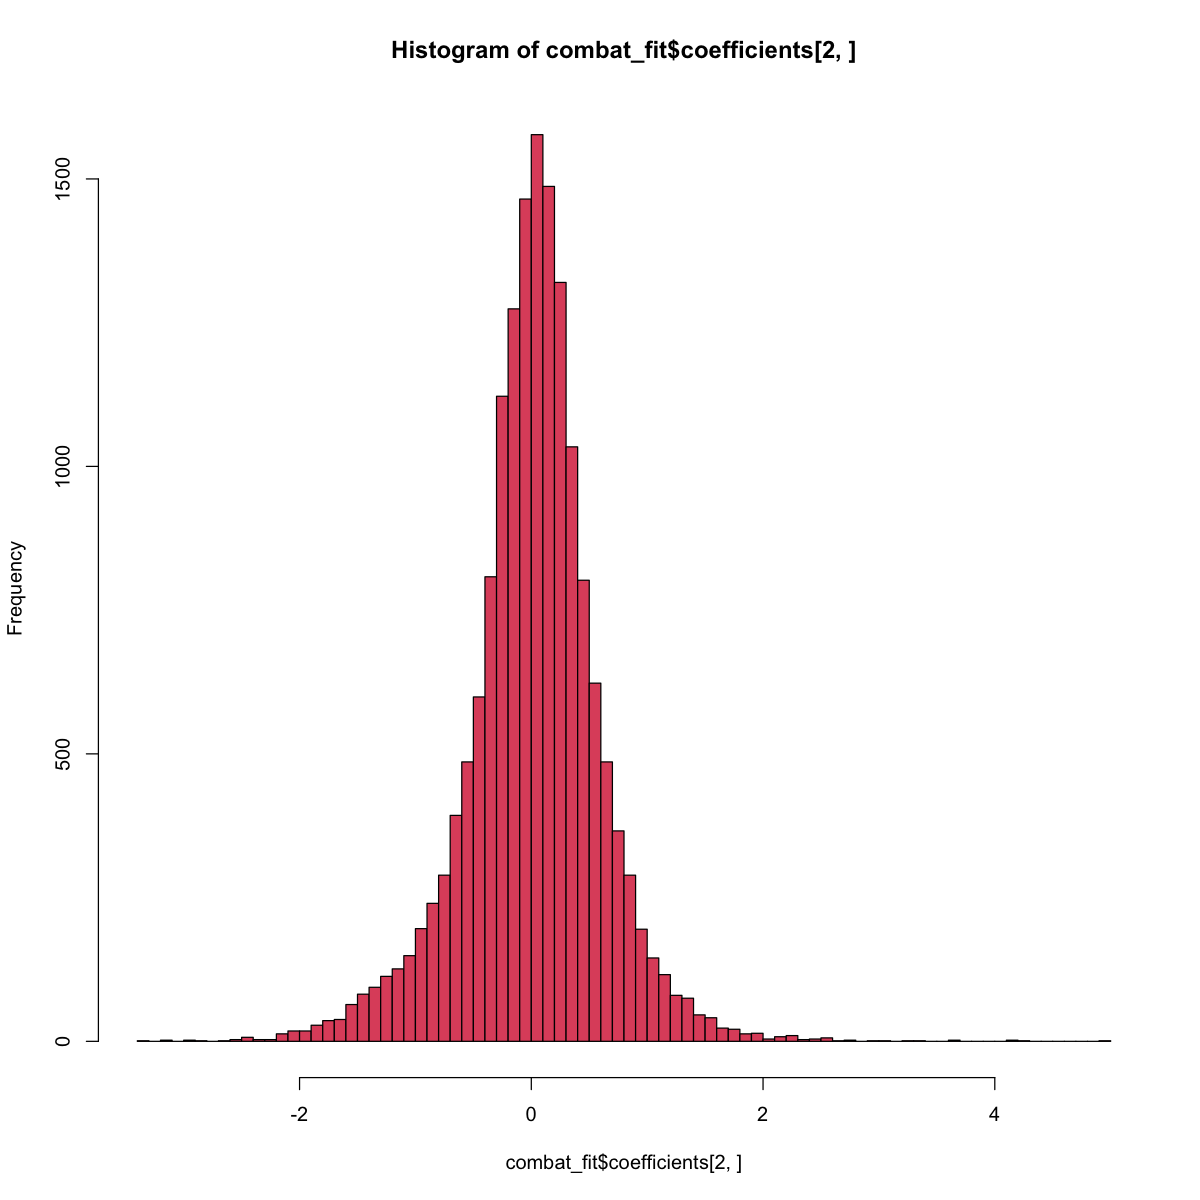

In [64]:
combat_fit = lm.fit(mod, t(mat_combat))
hist(combat_fit$coefficients[2,],col=2,breaks=100)

In [65]:
pca <- prcomp(t(mat_combat), scale. = TRUE)

In [66]:
pca_df <- as.data.frame(pca$x[, 1:2])
pca_df$sample <- rownames(pca_df)
pca_df$condition <- coldata[rownames(pca_df), "condition"]
pca_df$batch <- coldata[rownames(pca_df), "batch"]

percentVar <- (pca$sdev^2 / sum(pca$sdev^2))[1:2] * 100

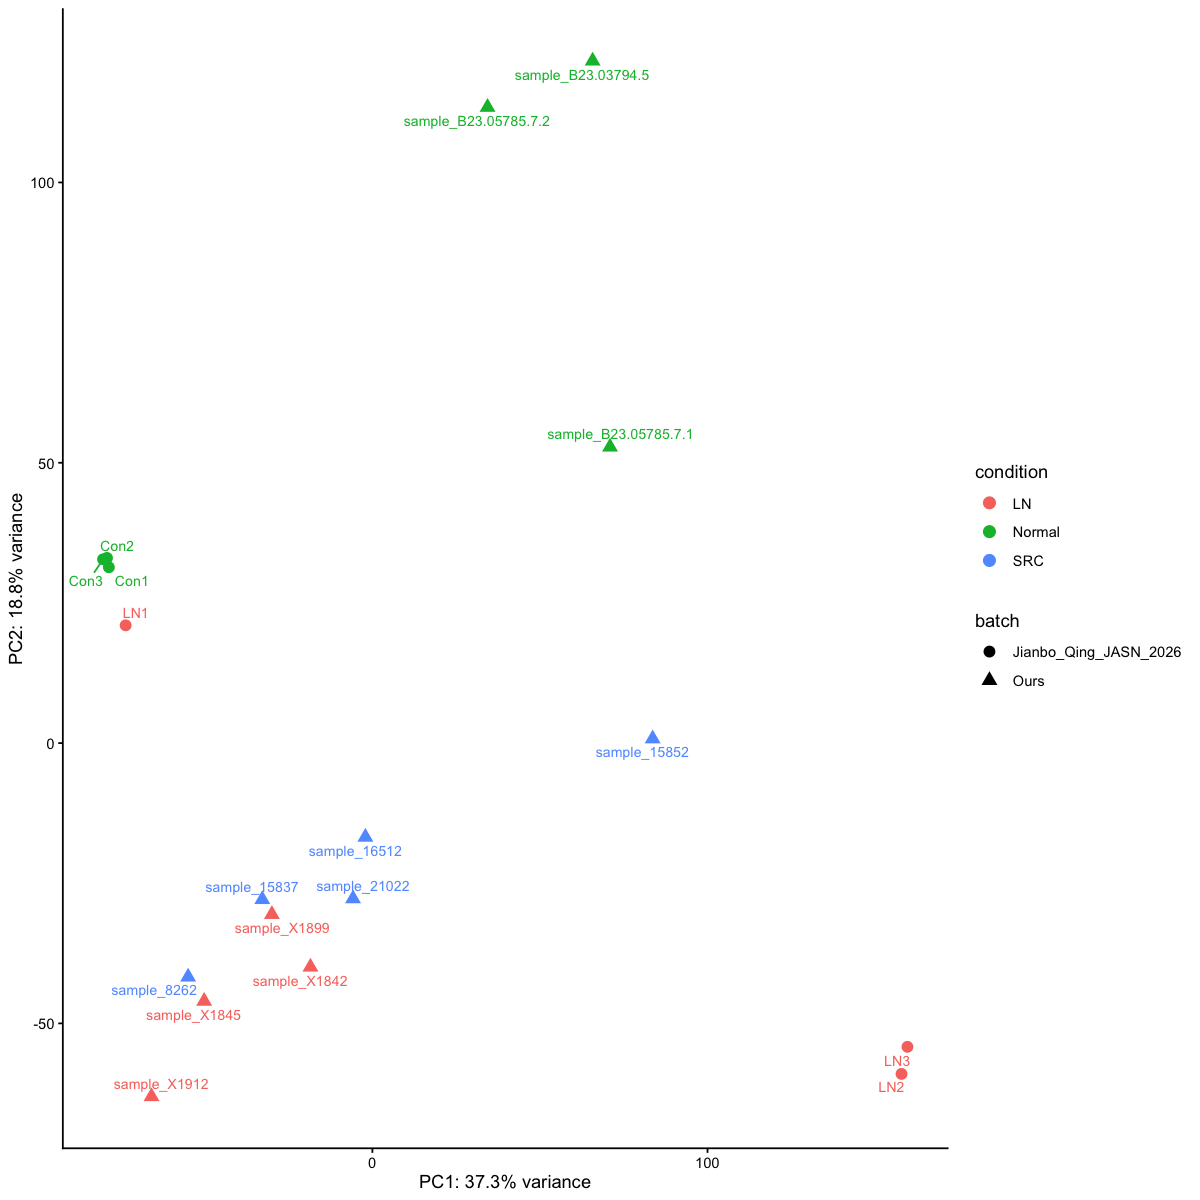

In [67]:
ggplot(pca_df, aes(PC1, PC2, color = condition, 
shape = batch, label = sample)) +
  geom_point(size = 3) +
  geom_text_repel(size = 3) +
  xlab(sprintf("PC1: %.1f%% variance", percentVar[1])) +
  ylab(sprintf("PC2: %.1f%% variance", percentVar[2])) +
  theme_classic()